Le variabili dummy

> **Per salvare il tuo lavoro scarica il notebook:** File → Scarica → Scarica .ipynb. Il file scaricato è tuo: per riaprirlo, su Colab File → Carica notebook, e da lì Salva funziona normalmente. Se hai aperto il notebook dal sito con *Apri in Colab*, non usare Salva: Colab proverebbe a salvarlo su GitHub.

In [ ]:
import polars as pl
from plotnine import *
import statsmodels.formula.api as smf #modelli statistici: crea da solo le variabili dummy

In [ ]:
car = pl.read_csv("https://www.vincnardelli.com/msd/dati/carseats.csv") #carico i dati dal sito
car.head()

Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
f64,i64,i64,i64,i64,i64,str,i64,i64,str,str
9.5,138,73,11,276,120,"""Bad""",42,17,"""Yes""","""Yes"""
11.22,111,48,16,260,83,"""Good""",65,10,"""Yes""","""Yes"""
10.06,113,35,10,269,80,"""Medium""",59,12,"""Yes""","""Yes"""
7.4,117,100,4,466,97,"""Medium""",55,14,"""Yes""","""Yes"""
4.15,141,64,3,340,128,"""Bad""",38,13,"""Yes""","""No"""


In [ ]:
car.filter(pl.col("US")== "Yes").select(pl.col("Sales").mean()) #vendite medie dei negozi negli Stati Uniti

Sales
f64
7.866899


In [ ]:
car.filter(pl.col("US")== "No").select(pl.col("Sales").mean()) #vendite medie dei negozi fuori dagli Stati Uniti

Sales
f64
6.823028


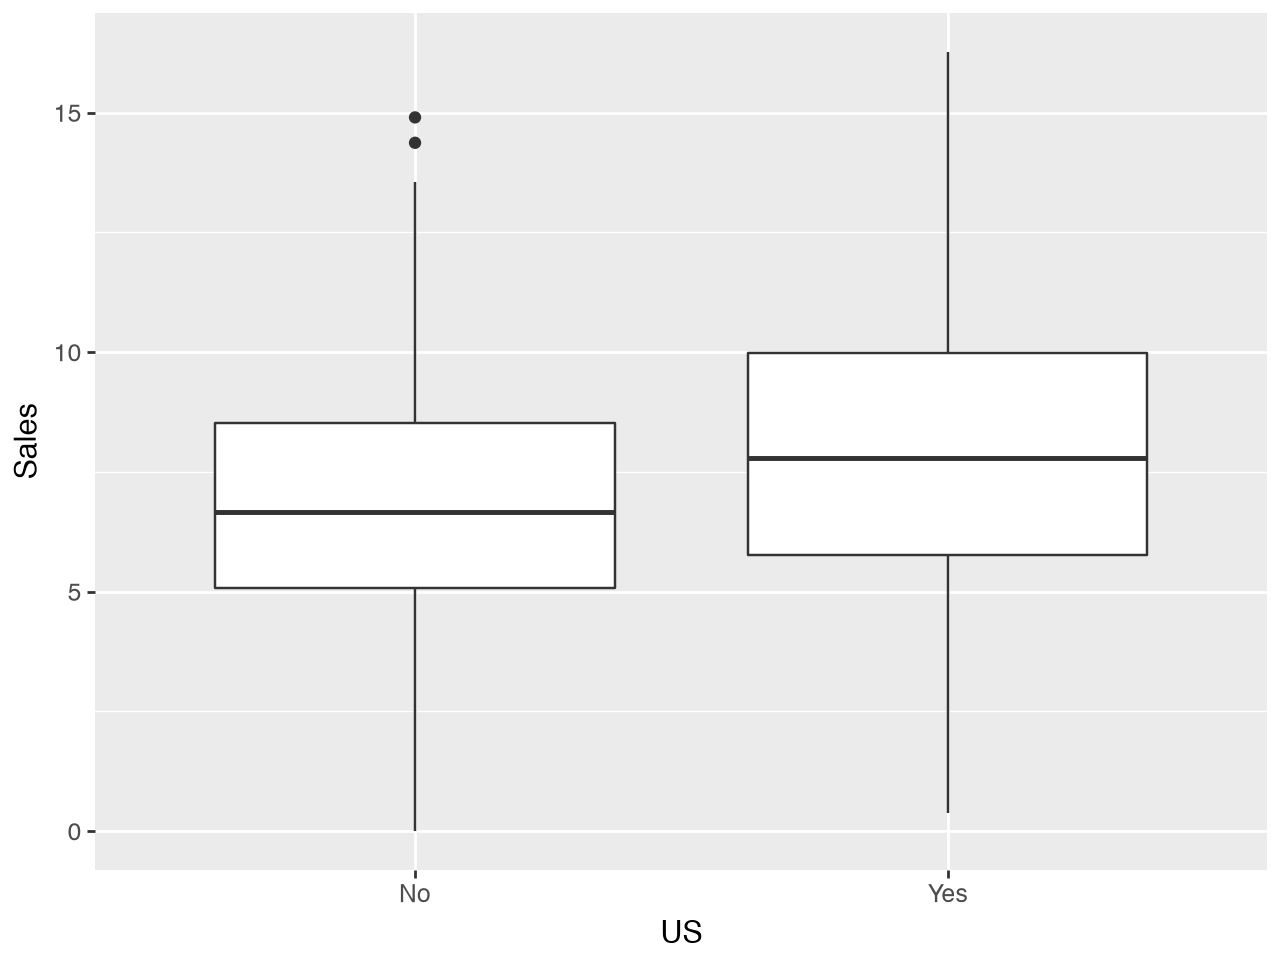

In [ ]:
ggplot(car, aes(x="US", y="Sales"))+geom_boxplot() #le vendite nei due gruppi

In [ ]:
#US è testo (Yes/No): la dummy US[T.Yes] la crea statsmodels
#la categoria di riferimento è No, la prima in ordine alfabetico
modello = smf.ols("Sales~US", data=car).fit()

In [ ]:
#intercetta 6.82: le vendite medie fuori dagli Stati Uniti
#US[T.Yes] 1.04: negli Stati Uniti in media 1.044 unità in più; p-value 0.000, significativa
modello.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.031
Model:                            OLS   Adj. R-squared:                  0.029
Method:                 Least Squares   F-statistic:                     12.89
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           0.000372
Time:                        14:05:05   Log-Likelihood:                -975.98
No. Observations:                 400   AIC:                             1956.
Df Residuals:                     398   BIC:                             1964.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.8230      0.234     29.215      0.000       6.364       7.282
US[T.Yes]      1.0439      0.291      3.590      0.000       0.472       1.616
==============================================================================
Omnibus:                        1.471   Durbin-Watson:                   1.902
Prob(Omnibus):                  0.479   Jarque-Bera (JB):                1.443
Skew:                           0.146   Prob(JB):                        0.486
Kurtosis:                       2.973   Cond. No.                         3.12
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

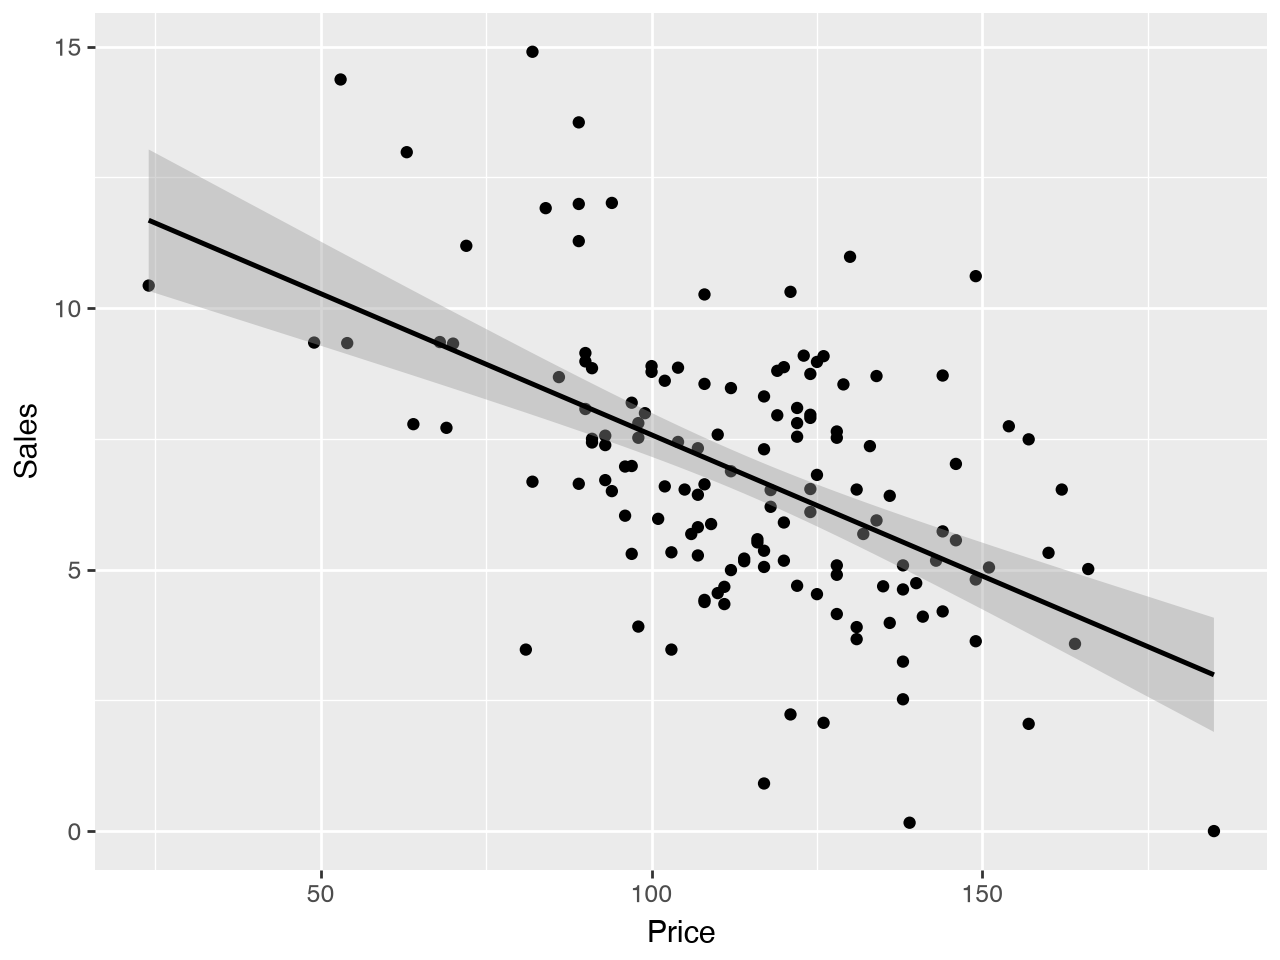

In [ ]:
#solo i negozi fuori dagli Stati Uniti: più prezzo, meno vendite
ggplot(car.filter(pl.col("US")=="No"),aes(x="Price", y="Sales"))+geom_point()+geom_smooth(method="lm")

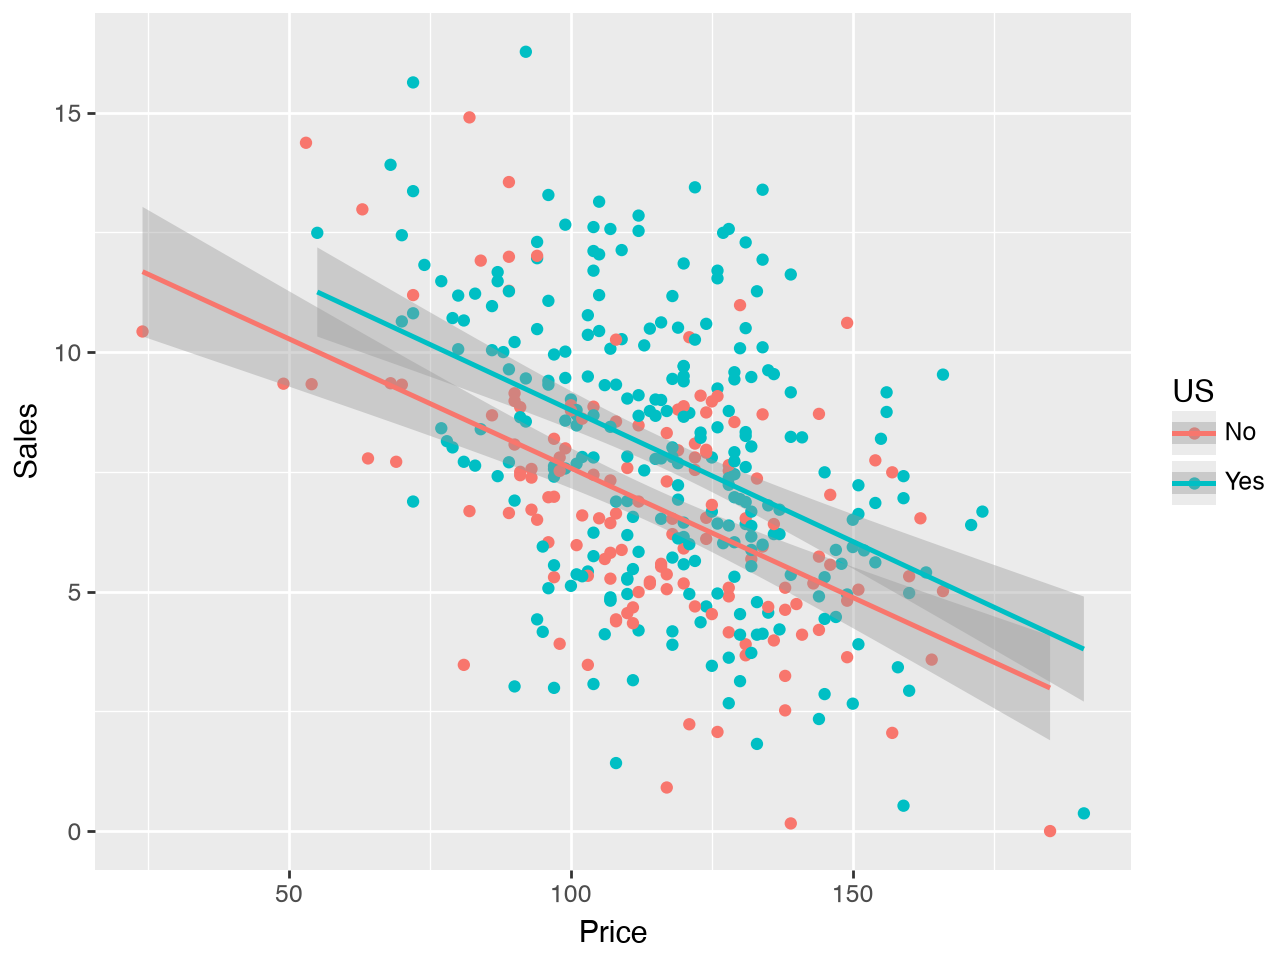

In [ ]:
#tutti i negozi: color="US" colora i punti secondo la colonna US, una retta per ogni gruppo
ggplot(car, aes(x="Price", y="Sales", color="US"))+geom_point()+geom_smooth(method="lm")

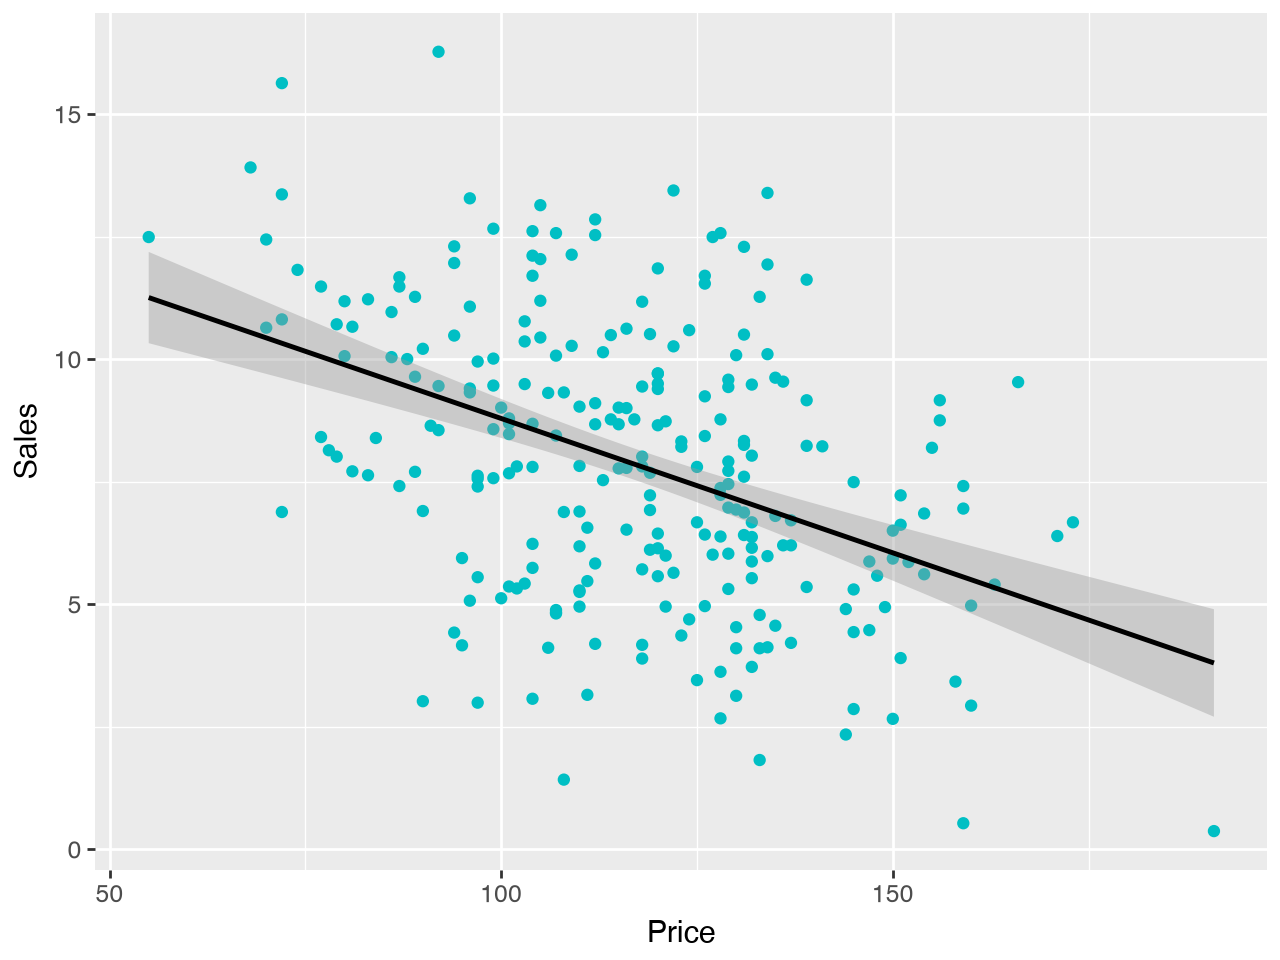

In [ ]:
#solo i negozi negli Stati Uniti, con lo stesso azzurro del grafico con tutti
#il comando va su una riga sola: andando a capo prima del + Python dà errore
ggplot(car.filter(pl.col("US") == "Yes"), aes(x="Price", y="Sales")) + geom_point(color="#00BFC4") + geom_smooth(method="lm")

In [ ]:
#a parità di prezzo: anche Price va nel modello
modello2=smf.ols("Sales~US+Price", data=car).fit()

In [ ]:
#US[T.Yes] 1.20: a parità di prezzo, negli Stati Uniti 1.200 unità in più
#Price -0.0545: a parità di paese, ogni dollaro in più, 54,5 unità in meno
modello2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     62.43
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           2.66e-24
Time:                        14:05:05   Log-Likelihood:                -927.66
No. Observations:                 400   AIC:                             1861.
Df Residuals:                     397   BIC:                             1873.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.0308      0.631     20.652      0.000      11.790      14.271
US[T.Yes]      1.1996      0.258      4.641      0.000       0.692       1.708
Price         -0.0545      0.005    -10.416      0.000      -0.065      -0.044
==============================================================================
Omnibus:                        0.666   Durbin-Watson:                   1.912
Prob(Omnibus):                  0.717   Jarque-Bera (JB):                0.749
Skew:                           0.092   Prob(JB):                        0.688
Kurtosis:                       2.895   Cond. No.                         607.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
#a predict diamo il valore di ogni x (US con il testo, come nei dati)
#con prezzo 120 dollari: 6.49 fuori dagli Stati Uniti, 7.69 negli Stati Uniti (migliaia di unità)
modello2.predict({"US":["No","Yes"], "Price":[120, 120]})

0    6.493477
1    7.693120
dtype: float64

In [ ]:
#ShelveLoc ha tre categorie (Bad, Good, Medium): statsmodels crea due dummy
modello3=smf.ols("Sales~ShelveLoc",data=car).fit()

In [ ]:
#intercetta 5.52: le vendite medie con scaffale Bad, la categoria di riferimento
#Good: 4.691 unità in più di Bad; Medium: 1.784 in più
modello3.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Sales   R-squared:                       0.317
Model:                            OLS   Adj. R-squared:                  0.314
Method:                 Least Squares   F-statistic:                     92.23
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           1.27e-33
Time:                        14:05:05   Log-Likelihood:                -906.03
No. Observations:                 400   AIC:                             1818.
Df Residuals:                     397   BIC:                             1830.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
Intercept               5.5229      0.239     23.131      0.000       5.054       5.992
ShelveLoc[T.Good]       4.6911      0.348     13.464      0.000       4.006       5.376
ShelveLoc[T.Medium]     1.7837      0.286      6.229      0.000       1.221       2.347
==============================================================================
Omnibus:                        0.077   Durbin-Watson:                   1.946
Prob(Omnibus):                  0.962   Jarque-Bera (JB):                0.092
Skew:                           0.033   Prob(JB):                        0.955
Kurtosis:                       2.966   Cond. No.                         4.57
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Anteprima: la regressione logistica, solo il codice. Come si legge lo vediamo dopo la lezione.

In [ ]:
#Y vale 1 se il coupon è accettato, 0 se no; expiration è la scadenza: 2h o 1d
coupon = pl.read_csv("https://www.vincnardelli.com/msd/dati/coupon.csv")
coupon.select("Y", "expiration").head()

Y,expiration
i64,str
1,"""1d"""
1,"""1d"""
0,"""2h"""
1,"""2h"""
0,"""2h"""


In [ ]:
#la y è 0/1: al posto di ols si usa logit
modello4=smf.logit("Y~expiration",data=coupon).fit()

Optimization terminated successfully.
         Current function value: 0.675309
         Iterations 4


In [ ]:
modello4.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                      Y   No. Observations:                12684
Model:                          Logit   Df Residuals:                    12682
Method:                           MLE   Df Model:                            1
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                 0.01235
Time:                        14:05:06   Log-Likelihood:                -8565.6
converged:                       True   LL-Null:                       -8672.7
Covariance Type:            nonrobust   LLR p-value:                 1.696e-48
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.5133      0.025     20.920      0.000       0.465       0.561
expiration[T.2h]    -0.5294      0.036    -14.586      0.000      -0.601      -0.458
====================================================================================
"""

In [ ]:
#predict dà una probabilità: un coupon che scade dopo 2 ore viene accettato con probabilità 0.50, dopo un giorno 0.63
modello4.predict({"expiration":["2h","1d"]})

0    0.495977
1    0.625582
dtype: float64